# Seismic inversion of a synthetic sand wedge, step by step

This notebook runs **pydelivery** (the Python port of CSIRO's Delivery) on a
small made-up example where we know the right answer.

The plan:

1. Invent a simple earth: a sand layer between two shales. The sand is thick
   on the left and thins to nothing (a **wedge**). It is filled with **gas**.
2. Make the seismic that this earth would produce, plus some noise.
3. Forget the truth. Give the inversion only the seismic and what an
   interpreter would roughly know beforehand (the *prior*).
4. Run the inversion. It returns many plausible earth models (*samples*)
   that fit the seismic and the prior.
5. Compare the answers with the truth.

Two questions make Delivery different from most inversions, and we will see
both answered:

* **Is the sand there at all, or has it pinched out?**
* **Is it filled with gas or brine?**

Everything runs in plain Python. Data files are written to a `wedge_data`
folder next to this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import pydelivery
from pydelivery import Inversion, StateModel, enumerate_fluid_states, load_config
from pydelivery.config import apply_prior_trace
from pydelivery.io import TraceSet, write_prior_table, write_traces
from pydelivery.seismic import build_seismic_model, load_wavelet

rng = np.random.default_rng(42)          # fixed seed: the notebook gives the same answer every run
work = Path("wedge_data")
work.mkdir(exist_ok=True)
print("pydelivery", pydelivery.__version__)

pydelivery 0.2.0


## Step 1: the wavelet

Seismic is the earth's layering seen through a blurry "lens": the
**wavelet**. Each boundary between layers sends back an echo shaped like the
wavelet, scaled by how different the two layers are.

We use a standard 30 Hz Ricker wavelet, sampled every 4 ms. It is centred on
time zero, so it starts at a negative time.

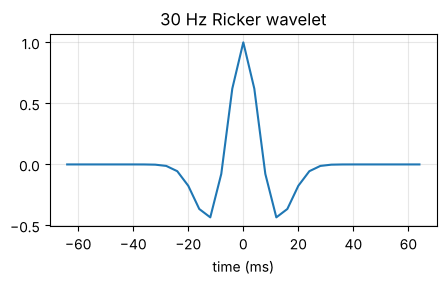

In [2]:
dt = 0.004                                   # sample interval, seconds
f = 30.0                                     # peak frequency, Hz
t_w = np.arange(-16, 17) * dt                # -64 ms ... +64 ms
wavelet = (1 - 2 * (np.pi * f * t_w) ** 2) * np.exp(-(np.pi * f * t_w) ** 2)

# a wavelet file is just one trace whose start time (t0) is negative
write_traces(work / "wavelet.h5", TraceSet(wavelet[None, :], dt, t_w[0]))

plt.figure(figsize=(5, 2.5))
plt.plot(1000 * t_w, wavelet)
plt.xlabel("time (ms)"); plt.title("30 Hz Ricker wavelet"); plt.grid(alpha=0.3)
plt.show()

## Step 2: describe the model in Delivery's XML

Delivery describes the problem in an XML file. Ours has three layers:

| Layer | Rock | What we tell the inversion |
|---|---|---|
| 1. Seal | shale | its top time (picked well, ±5 ms) |
| 2. Reservoir | sand mixed with shale (net-to-gross about 0.8) | its top time ±5 ms; **50 % chance of gas, 50 % brine** |
| 3. Base | shale | its top time (= base of the sand) ±10 ms |

The rock properties come from **trend curves**: rules like "sand velocity is
about 3000 m/s, give or take 150". The fluid properties of brine and gas
are given too. Delivery combines these with **Gassmann's equation** to work
out how gas changes the sand's velocity and density.

With these numbers a brine-filled sand looks almost like the shale around it
(a reflection coefficient of about -0.01: nearly invisible), but gas makes the
sand much softer and lighter (about -0.12): a **bright spot**. That contrast
is what lets the seismic tell gas from brine.

The `varies_areally="true"` flags say that some values change from trace to
trace; we will supply those in a small table in Step 4.

In [3]:
xml = """<?xml version="1.0"?>
<inversion>
  <seismic_data>
    <stack>
      <name>near</name>
      <filename>stack.h5</filename>
      <min_offset>0</min_offset><max_offset>1000</max_offset>
      <reflector_time>1900</reflector_time><stack_velocity>2500</stack_velocity>
      <wavelet><filename>wavelet.h5</filename><noise_rms>0.01</noise_rms></wavelet>
    </stack>
    <AVO_terms><A>1.0</A><B>1.0</B></AVO_terms>
  </seismic_data>

  <model_description>
    <top_layer>
      <name>seal</name>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time>1800</time><sigma_time>5</sigma_time>
      <net_to_gross>0</net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
    </top_layer>
    <middle_layer>
      <name>reservoir sand</name>
      <reservoir_endmember>
        <name>sand</name>
        <brine><name>brine</name></brine>
        <gas><name>gas</name>
          <probability_of_gas>0.5</probability_of_gas>
          <saturation_of_gas>0.8</saturation_of_gas>
        </gas>
      </reservoir_endmember>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time varies_areally="true">1900</time><sigma_time>5</sigma_time>
      <net_to_gross>0.8</net_to_gross><sigma_net_to_gross>0.1</sigma_net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
    </middle_layer>
    <bottom_layer>
      <name>base shale</name>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time varies_areally="true">1940</time><sigma_time>10</sigma_time>
      <net_to_gross>0</net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
      <t_base>2050</t_base><sigma_t_base>5</sigma_t_base>
    </bottom_layer>
  </model_description>

  <rock_fluid_properties>
    <fluid_properties>
      <fluid><name>brine</name><vp>1750</vp><sigma_vp>0</sigma_vp><rho>1050</rho><sigma_rho>0</sigma_rho></fluid>
      <fluid><name>gas</name><vp>550</vp><sigma_vp>50</sigma_vp><rho>150</rho><sigma_rho>30</sigma_rho></fluid>
    </fluid_properties>
    <rock_properties>
      <reservoir_endmember><name>sand</name><reference_fluid>brine</reference_fluid>
        <vp_curve><intercept>3000</intercept><depth_coefficient>0</depth_coefficient>
                  <LFIV_coefficient>0</LFIV_coefficient><sigma>150</sigma></vp_curve>
        <vs_curve><intercept>-733</intercept><slope>0.768</slope><sigma>100</sigma></vs_curve>
        <porosity_curve><intercept>0.655</intercept><slope>-0.0001183</slope><sigma>0.02</sigma></porosity_curve>
        <vp_grain>6110</vp_grain><vs_grain>4131</vs_grain><rho_grain>2649</rho_grain>
      </reservoir_endmember>
      <nonreservoir_endmember><name>shale</name>
        <vp_curve><intercept>2812</intercept><depth_coefficient>0</depth_coefficient>
                  <LFIV_coefficient>0</LFIV_coefficient><sigma>100</sigma></vp_curve>
        <vs_curve><intercept>-496</intercept><slope>0.57</slope><sigma>43</sigma></vs_curve>
        <density_curve><factor>300</factor><exponent>0.26</exponent><sigma>20</sigma></density_curve>
      </nonreservoir_endmember>
    </rock_properties>
  </rock_fluid_properties>

  <output><density_ordering>full</density_ordering></output>
</inversion>
"""
(work / "ModelDescription.xml").write_text(xml)
cfg = load_config(work / "ModelDescription.xml")
print([lay.name for lay in cfg.layers])
print("possible fluid states:", [(s.label, s.probability) for s in enumerate_fluid_states(cfg)])

['seal', 'reservoir sand', 'base shale']
possible fluid states: [('bbb', 0.5), ('bgb', 0.5)]


The fluid states are written one letter per layer: `b` = brine, `g` = gas.
Only the sand can hold gas, so there are two possibilities, `bbb` and `bgb`,
each with prior probability 0.5.

## Step 3: the true earth (which the inversion will not see)

Twenty traces across the wedge. The sand top is at 1900 ms everywhere. Its
thickness (in two-way time) shrinks from 40 ms on the left to zero at
trace 14; from there on the sand is absent. The sand holds gas.

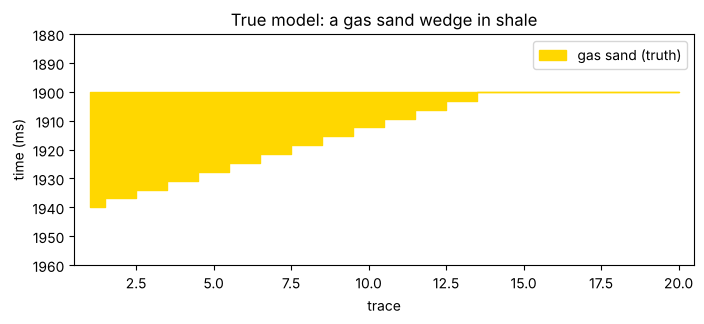

In [4]:
n_traces = 20
x = np.arange(1, n_traces + 1)
top_true = np.full(n_traces, 1.900)                                 # seconds
thick_true = np.clip(0.040 * (1 - (x - 1) / 13), 0, None)           # 40 ms -> 0 at trace 14
base_true = top_true + thick_true

plt.figure(figsize=(8, 3))
plt.fill_between(x, 1000 * top_true, 1000 * base_true, step="mid", color="gold", label="gas sand (truth)")
plt.gca().invert_yaxis()
plt.xlabel("trace"); plt.ylabel("time (ms)"); plt.xlim(0.5, n_traces + 0.5); plt.ylim(1960, 1880)
plt.title("True model: a gas sand wedge in shale"); plt.legend(); plt.show()

## Step 4: what the interpreter knows (the prior table)

Before inverting, an interpreter has picked horizons on the seismic. Picks
are never perfect, so we add a few milliseconds of random error to the true
times. These picks become the **prior means**; the `sigma_time` values in the
XML say how far off they might be.

Notice what happens on the right: where the true sand is absent the base pick
sits on (or even above) the top pick. The inversion has to decide from the
seismic whether the sand is really there.

Per-trace values go in a *prior table*: one named array per XML tag. Times
are in milliseconds, with the bottom of the model (`t_base`) as the last
column. `NaN` means "use the value in the XML".

In [5]:
top_pick = top_true + rng.normal(0, 0.003, n_traces)
base_pick = base_true + rng.normal(0, 0.006, n_traces)

times = np.full((n_traces, 4), np.nan)        # columns: seal top, sand top, base-shale top, t_base
times[:, 1] = 1000 * top_pick
times[:, 2] = 1000 * base_pick
write_prior_table(work / "priors.h5", {"time": times})
print(np.round(times[:, 1:3], 1))

[[1900.9 1938.9]
 [1896.9 1932.8]
 [1902.3 1941.2]
 [1902.8 1929.8]
 [1894.1 1925.1]
 [1896.1 1922.5]
 [1900.4 1924.7]
 [1899.1 1920.7]
 [1899.9 1917.9]
 [1897.4 1914.9]
 [1902.6 1922.1]
 [1902.3 1903.7]
 [1900.2 1900. ]
 [1903.4 1895.1]
 [1901.4 1903.7]
 [1897.4 1906.8]
 [1901.1 1899.3]
 [1897.1 1895. ]
 [1902.6 1895.1]
 [1899.9 1903.9]]


## Step 5: make the synthetic seismic

We ask pydelivery's own forward model what seismic the true earth produces.
For each trace:

* take the prior settings for that trace,
* set the layer times to the truth and choose the gas fluid state,
* compute the synthetic trace (reflection coefficients convolved with the
  wavelet),
* add random noise at the level stated in the XML (0.01, about a tenth
  of the gas-sand echo).

The result is written to `stack.h5`, the file the XML points to.

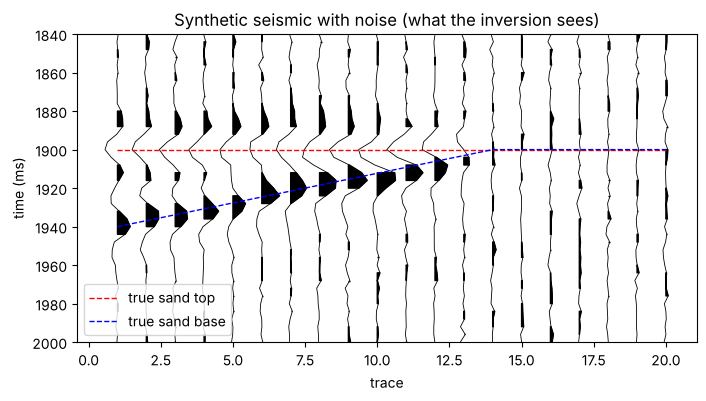

In [6]:
table = {"time": times}
w = load_wavelet(work / "wavelet.h5")
t0, ns = 1.700, 150                                 # seismic traces start at 1700 ms, 150 samples
data = np.zeros((n_traces, ns))
for i in range(n_traces):
    cfg_i = apply_prior_trace(cfg, table, i)
    blank = TraceSet(np.zeros((1, ns)), dt, t0)[0]
    seis = build_seismic_model(cfg_i, [blank], [w])
    gas = next(s for s in enumerate_fluid_states(cfg_i) if s.label == "bgb")
    model = StateModel(cfg_i, gas, seis)
    m = model.prior_mean.copy()                       # typical rock properties ...
    m[model.index[("t", 1)]] = top_true[i]            # ... but the true times
    m[model.index[("t", 2)]] = base_true[i]
    synthetic = model.synthetics(m[None])[0][0]
    j0 = int(round((seis.t_start - t0) / dt))
    data[i, j0:j0 + seis.ns] = synthetic

noise = rng.normal(0, 0.01, data.shape)
write_traces(work / "stack.h5", TraceSet(data + noise, dt, t0))

def wiggles(d, title):
    t = 1000 * (t0 + dt * np.arange(ns))
    plt.figure(figsize=(8, 4))
    for k, tr in enumerate(d):
        s = k + 1 + tr / 0.25
        plt.plot(s, t, "k", lw=0.6)
        plt.fill_betweenx(t, k + 1, s, where=s > k + 1, color="k")
    plt.gca().invert_yaxis(); plt.ylim(2000, 1840)
    plt.xlabel("trace"); plt.ylabel("time (ms)"); plt.title(title)

wiggles(data + noise, "Synthetic seismic with noise (what the inversion sees)")
plt.plot(x, 1000 * top_true, "r--", lw=1, label="true sand top")
plt.plot(x, 1000 * base_true, "b--", lw=1, label="true sand base")
plt.legend(loc="lower left"); plt.show()

The gas sand gives a strong trough at its top (white) and a strong peak at its
base (black). As the wedge thins the two echoes move together and merge
(*tuning*); from trace 14 on, where the sand is gone, only noise is left.

## Step 6: run the inversion

From here on we use only the files: the XML, the seismic, the wavelet and the
prior table. At each trace pydelivery:

1. lists the possible fluid states (`bbb`, `bgb`),
2. finds the best-fitting models for each (there can be several, e.g. sand
   present or pinched out),
3. runs a Markov chain Monte Carlo sampler that wanders between all of them,
   spending time in each in proportion to how probable it is.

We ask for 1000 samples per trace. This takes about a minute.

In [7]:
inv = Inversion.from_files(work / "ModelDescription.xml", work / "priors.h5")
results = inv.run(n_samples=1000, seed=1)
inv.save(work / "results.h5", results)
print(f"{len(results)} traces x {results[0].n_samples} samples, saved to {work / 'results.h5'}")

20 traces x 1000 samples, saved to wedge_data/results.h5


## Step 7: what the inversion found

Each trace now has 1000 plausible earth models. Instead of a single answer we
get **ranges**: the P10, P50 (median) and P90 of any property, and the
probability of anything we can count.

### Is the sand there, and how thick is it?

The orange band is the P10–P90 range of the sand thickness (in milliseconds
of two-way time) across the samples; the line is the median. The dashed line
is the truth.

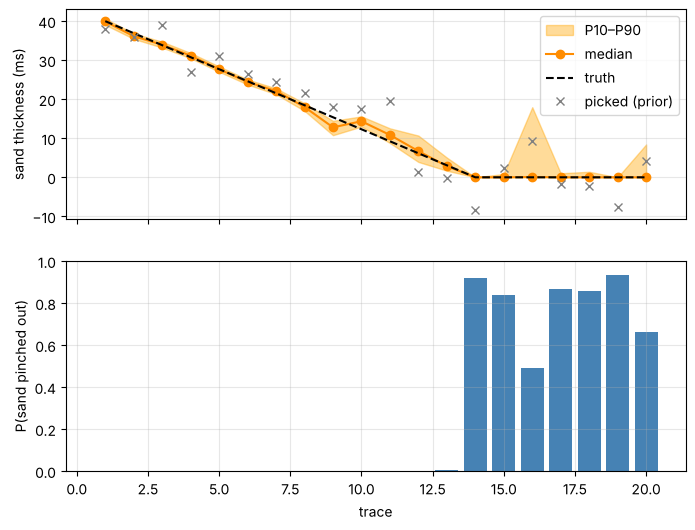

In [8]:
thick = np.array([1000 * (r.samples["t"][:, 2] - r.samples["t"][:, 1]) for r in results])
p10, p50, p90 = np.percentile(thick, [10, 50, 90], axis=1)
pinch = np.array([r.pinchout_probability()[1] for r in results])

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].fill_between(x, p10, p90, color="orange", alpha=0.4, label="P10–P90")
ax[0].plot(x, p50, "o-", color="darkorange", label="median")
ax[0].plot(x, 1000 * thick_true, "k--", label="truth")
ax[0].plot(x, times[:, 2] - times[:, 1], "x", color="gray", label="picked (prior)")
ax[0].set_ylabel("sand thickness (ms)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].bar(x, pinch, color="steelblue")
ax[1].set_ylabel("P(sand pinched out)"); ax[1].set_xlabel("trace"); ax[1].set_ylim(0, 1); ax[1].grid(alpha=0.3)
plt.show()

* Where the sand is present (traces 1–13) the inversion follows the true
  thickness closely, much more closely than the noisy picks it started from
  (grey crosses). The seismic, not the picks, is now setting the answer.
* Where the sand is absent (traces 14–20) the inversion gives a real
  **probability that the sand has pinched out**, between about 65 and 95 %, rather than
  a forced yes/no or a small made-up thickness. At trace 16 the pick claimed
  9 ms of sand; the probability there is about 50 % and the thickness range
  widens: the inversion is weighing the pick against the absence of an echo.

### Gas or brine?

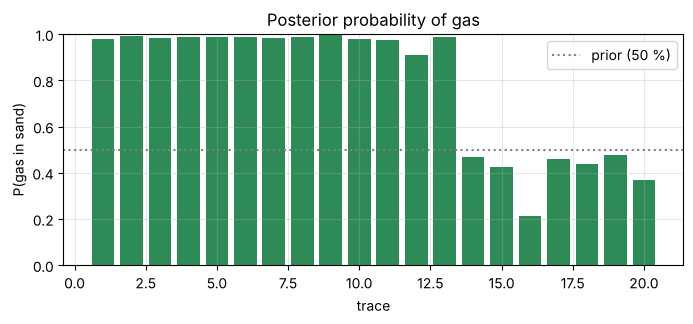

In [9]:
p_gas = np.array([r.fluid_probabilities()[1, 3] for r in results])
p_gas = np.where(pinch < 1, p_gas, np.nan)    # fluid is meaningless where the sand is always absent

plt.figure(figsize=(8, 3))
plt.bar(x, p_gas, color="seagreen")
plt.axhline(0.5, color="gray", ls=":", label="prior (50 %)")
plt.ylim(0, 1); plt.xlabel("trace"); plt.ylabel("P(gas in sand)")
plt.title("Posterior probability of gas"); plt.legend(); plt.grid(alpha=0.3); plt.show()

* Where the sand is present the prior's 50/50 becomes **90–100 % gas**: a
  brine sand would be nearly invisible, but we see a bright spot.
* Where the sand is absent there is nothing to measure, so the answer stays
  near the prior. It is a little *below* 50 %: if any sand were there, a gas
  sand would have shown up as an echo, a thin brine sand would not, so the
  small remaining chance of sand is more likely brine.

The inversion is honest about what the data can and cannot tell it.

### How well do the samples fit the seismic?

Finally, a check: the synthetic seismic of the most probable model at each
trace (the peak of its most probable mode), compared with the data. A good
fit means the inversion explains what we observed. The normalised misfit
(`seismic_chisquare`) measures the remaining mismatch in units of the
declared noise; values around 1 mean the model explains everything except
the noise.

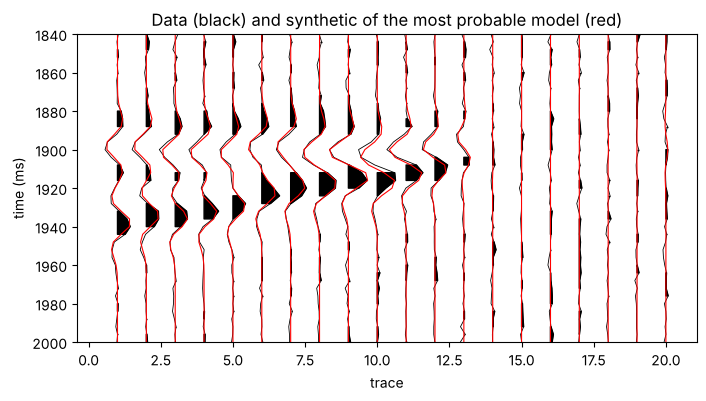

mean normalised seismic misfit per trace: [0.44 0.83 1.08 0.66 0.71 0.83 0.61 0.95 1.19 0.75 0.6  0.66 0.72 1.5
 0.44 0.65 1.09 0.33 0.84 0.99]


In [10]:
fit = np.zeros_like(data)
for i, r in enumerate(results):
    best = max(r.modes, key=lambda mo: mo.weight)      # most probable mode
    seis = best.model.seismic
    syn = best.model.synthetics(best.mean[None])[0][0]
    j0 = int(round((seis.t_start - t0) / dt))
    fit[i, j0:j0 + seis.ns] = syn

wiggles(data + noise, "Data (black) and synthetic of the most probable model (red)")
t = 1000 * (t0 + dt * np.arange(ns))
for k, tr in enumerate(fit):
    plt.plot(k + 1 + tr / 0.25, t, "r", lw=0.8)
plt.show()
print("mean normalised seismic misfit per trace:",
      np.round([r.samples["seismic_chisquare"].mean() for r in results], 2))

## Summary

* We built a gas sand wedge, made its seismic, and inverted it knowing only
  rough horizon picks and rock-physics trends.
* The inversion recovered the sand thickness wherever the sand exists, and
  gave a **probability of pinch-out** where it vanishes.
* It turned a 50/50 prior on gas into near-certainty where the seismic shows
  the gas bright spot, and stayed near the prior where there is no sand.
* All results are in `wedge_data/results.h5`, one array per property with
  shape (traces, samples, layers). Load them with
  `pydelivery.read_results("wedge_data/results.h5")`, or summarise from the
  command line with `pydelivery summary wedge_data/results.h5 --property NG`.

To try your own variations, change the XML (e.g. the gas probability, the
noise level, the sigma of the picks) or the true model in Step 3 and re-run.
A good first experiment: set the sand velocity intercept back to 3500 m/s.
Brine sand then becomes bright and gas sand dim, and the evidence for gas
comes from the *absence* of an echo instead.